# L2_T3 — Train the Baseline Skin-Condition Classifier
### Layer 2 of the Aura pipeline · Task 3

**What this notebook does:** cleans the T2 label set (fixing the contamination found in the T2 review), splits it
without near-duplicate leakage, trains an EfficientNet-B0 classifier on DermNet's three mapped categories, evaluates
it honestly, and exports a TFLite model.

**Read this first — a correction to the plan.** Earlier notes said Layer 2 would train with a *masked loss*.
That only helps when some images carry negative labels. DermNet gives each image exactly **one** positive and
*unknown* for the rest, so a masked multi-label loss on this data has no negatives and collapses to "predict
everything". The only honest formulation DermNet supports is a **3-way softmax: "which of these three conditions
does this image show?"**. A true multi-label head needs data with negatives (SkinCon, ACNE04 severity, in-house
selfies) — that comes in a later task.

**What this model is and isn't:**
- It is a *baseline* that proves the pipeline end to end on ~900 clinical images.
- It has **no healthy-skin class**: a clear-skin selfie will still be forced into one of the three conditions.
  It must not be shown to users as a diagnosis or a skin "score".
- It was trained on clinical close-ups, not selfies. Expect a domain gap.
- Dryness/oiliness and pore visibility are **not** modeled (no data).

**Run order:** Runtime → GPU (T4 is fine). Run cells top to bottom.

## Step 0 — Mount Drive, load manifest

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, time, shutil, tarfile

DRIVE_ROOT = "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition"
MANIFEST_PATH = f"{DRIVE_ROOT}/manifest.json"
assert os.path.exists(MANIFEST_PATH), "manifest.json not found -- did L2_T2 finish?"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)
assert "preprocessing" in manifest, "L2_T2 has not updated the manifest."

PP_ARCHIVE = manifest["preprocessing"]["drive_archive"]
assert os.path.exists(PP_ARCHIVE), f"Missing {PP_ARCHIVE}"
print("Preprocessed archive:", PP_ARCHIVE)
print("Expected images:", manifest["preprocessing"]["images_processed"])

LOCAL_ROOT = "/content/aura_local/Layer2_SkinCondition"
LOCAL_DATA = f"{LOCAL_ROOT}/t3_data"
LOCAL_MODEL = f"{LOCAL_ROOT}/models"
DRIVE_MODEL_DIR = f"{DRIVE_ROOT}/models"
for d in (LOCAL_DATA, LOCAL_MODEL, DRIVE_MODEL_DIR):
    os.makedirs(d, exist_ok=True)


Mounted at /content/drive
Preprocessed archive: /content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition/preprocessed/dermnet_conditions_preprocessed.tar.gz
Expected images: 983


## Step 1 — GPU check and dependencies

In [ ]:
import tensorflow as tf
print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
if not gpus:
    print("⚠️ No GPU. Runtime -> Change runtime type -> T4 GPU. Training will be slow on CPU.")


TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip -q install scikit-learn pandas matplotlib seaborn
print("Dependencies ready.")


Dependencies ready.


## Step 2 — Copy archive locally and extract (copy first, then extract, to avoid Drive transport errors)

In [ ]:
local_archive = f"{LOCAL_ROOT}/dermnet_conditions_preprocessed.tar.gz"
shutil.copy2(PP_ARCHIVE, local_archive)
print(f"Copied ({os.path.getsize(local_archive)/1e6:.1f} MB)")

shutil.rmtree(LOCAL_DATA, ignore_errors=True); os.makedirs(LOCAL_DATA)
with tarfile.open(local_archive, "r:gz") as tar:
    tar.extractall(LOCAL_DATA, filter="data")

DATA_DIR = f"{LOCAL_DATA}/dermnet_conditions_preprocessed"
CSV = f"{DATA_DIR}/processed_labels.csv"
assert os.path.exists(CSV), "processed_labels.csv missing from archive"
n_jpg = sum(1 for f in os.listdir(DATA_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png")))
print("Images extracted:", n_jpg)
assert n_jpg == manifest["preprocessing"]["images_processed"], "Image count mismatch"
print("✅ Extraction verified.")


Copied (22.8 MB)
Images extracted: 983
✅ Extraction verified.


## Step 3 — Clean the labels (fixes the T2 review findings)
T2's output showed the **pigmentation** class contains skin cancers (`basal cell carcinoma pigmented`, 60 images;
`actinic keratosis pigmented`, 9) and `pigmented bands`, and **acne** contains `nevus comedonicus`. None of those
are what a cosmetic pigmentation/acne category means, and a model trained on them would learn *lesion type*, not
the target. They are dropped here from the T2 CSV, so you do **not** need to re-run T2.
Edit `DROP_LABEL_KEYWORDS` if you disagree.

In [ ]:
import pandas as pd
df = pd.read_csv(CSV)
print("Rows before cleaning:", len(df))
print(df["aura_condition"].value_counts().to_string())

DROP_LABEL_KEYWORDS = ["basal cell", "carcinoma", "keratosis", "nevus comedonicus", "pigmented bands"]
bad = df["label_norm"].apply(lambda l: any(k in l for k in DROP_LABEL_KEYWORDS))
print("\nDropping:")
print(df[bad].groupby(["aura_condition", "label_norm"]).size().to_string())

df = df[~bad].reset_index(drop=True)
print("\nRows after cleaning:", len(df))
print(df["aura_condition"].value_counts().to_string())

CLASSES = sorted(df["aura_condition"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["aura_condition"].map(class_to_idx)
print("\nClasses:", class_to_idx)
smallest = df["aura_condition"].value_counts().min()
if smallest < 150:
    print(f"⚠️ Smallest class has only {smallest} images -- metrics on it will be noisy.")


Rows before cleaning: 983
aura_condition
acne                   374
redness_sensitivity    311
pigmentation           298

Dropping:
aura_condition  label_norm                    
acne            nevus comedonicus                  6
pigmentation    actinic keratosis pigmented        9
                basal cell carcinoma pigmented    60
                pigmented bands                    8

Rows after cleaning: 900
aura_condition
acne                   368
redness_sensitivity    311
pigmentation           221

Classes: {'acne': 0, 'pigmentation': 1, 'redness_sensitivity': 2}


## Step 4 — Leakage-aware split
DermNet has no patient or lesion IDs, and many images are near-duplicates of each other. A random split would put
twins in train and test and inflate every metric. Near-duplicates are grouped with a perceptual hash
(dHash, Hamming distance ≤ 6), and **whole groups** are assigned to one split.

In [ ]:
import numpy as np
from PIL import Image

def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

hashes = np.stack([dhash(f"{DATA_DIR}/{f}") for f in df["processed_filename"]])

# union-find over near-duplicates
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
HAM = 6
n_links = 0
for i in range(len(df)):
    d = (hashes[i + 1:] != hashes[i]).sum(axis=1)
    for j in np.where(d <= HAM)[0] + i + 1:
        ri, rj = find(i), find(j)
        if ri != rj:
            parent[rj] = ri; n_links += 1
df["group"] = [find(i) for i in range(len(df))]
print(f"{df['group'].nunique()} groups from {len(df)} images ({n_links} near-duplicate links merged)")

from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(sgkf.split(df, df["y"], df["group"]))
test_idx, val_idx = folds[0][1], folds[1][1]
train_idx = np.setdiff1d(np.arange(len(df)), np.concatenate([test_idx, val_idx]))
df["split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

print(pd.crosstab(df["split"], df["aura_condition"]).to_string())
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(df[df.split == a]["group"]) & set(df[df.split == b]["group"])), f"Leak {a}/{b}"
print("✅ No duplicate group spans two splits.")


853 groups from 900 images (47 near-duplicate links merged)
aura_condition  acne  pigmentation  redness_sensitivity
split                                                  
test              71            44                   56
train            225           130                  194
val               72            47                   61
✅ No duplicate group spans two splits.


## Step 5 — Data pipeline (mild augmentation; **no hue/saturation jitter** — colour is the signal for redness and pigmentation)

In [ ]:
IMG = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load(path, y):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.float32), y   # EfficientNet in Keras rescales internally (expects 0-255)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.1),
])

def make_ds(sub, train):
    paths = [f"{DATA_DIR}/{f}" for f in sub["processed_filename"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, sub["y"].values.astype("int32")))
    if train:
        ds = ds.shuffle(len(sub), seed=1)
    ds = ds.map(load, num_parallel_calls=AUTOTUNE)
    if train:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_df, val_df, test_df = (df[df.split == s] for s in ("train", "val", "test"))
train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df["y"].values)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {CLASSES[i]: round(w, 2) for i, w in class_weight.items()})


Class weights: {'acne': 0.81, 'pigmentation': 1.41, 'redness_sensitivity': 0.94}


## Step 6 — Model: frozen EfficientNet-B0 backbone, then partial fine-tune

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False

inp = keras.Input((IMG, IMG, 3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inp, out)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks = [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss")]

print("--- Stage 1: head only ---")
h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=callbacks)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
--- Stage 1: head only ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.4444 - loss: 1.0946 - val_accuracy: 0.6278 - val_loss: 0.8693
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 395ms/step - accuracy: 0.6357 - loss: 0.8377 - val_accuracy: 0.6778 - val_loss: 0.7769
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 330ms/step - accuracy: 0.7086 - loss: 0.7174 - val_accuracy: 0.7056 - val_loss: 0.7189
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 429ms/step - accuracy: 0.7177 - loss: 0.6817 - val_accuracy: 0.6944 - val_loss: 0.6887
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 321ms/step - accuracy: 0.7577 - loss: 0.6387 - val_accuracy: 0.7389 - val_loss: 0.6624
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 324ms/step - accuracy: 0.7632 - loss: 0.6224 - val_accuracy: 0.7333 - val_loss: 0.6415
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 416ms/step - accuracy: 0.7741 - loss: 0.5837 - val_accuracy: 0.7611 - val_loss: 0.6168
Epoch 8/15
18/18 ━━━━━━━━━

In [ ]:
print("--- Stage 2: unfreeze top 20 layers (BatchNorm kept frozen) ---")
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight,
               callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss")])


--- Stage 2: unfreeze top 20 layers (BatchNorm kept frozen) ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8233 - loss: 0.4792 - val_accuracy: 0.8278 - val_loss: 0.5362
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step - accuracy: 0.8361 - loss: 0.4350 - val_accuracy: 0.8389 - val_loss: 0.5312
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 394ms/step - accuracy: 0.8488 - loss: 0.4338 - val_accuracy: 0.8333 - val_loss: 0.5293
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 442ms/step - accuracy: 0.8379 - loss: 0.4359 - val_accuracy: 0.8389 - val_loss: 0.5264
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 336ms/step - accuracy: 0.8197 - loss: 0.4319 - val_accuracy: 0.8333 - val_loss: 0.5247
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 434ms/step - accuracy: 0.8270 - loss: 0.4280 - val_accuracy: 0.8333 - val_loss: 0.5231
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 326ms/step - accuracy: 0.8561 - loss: 0.3989 - val_accuracy: 0.8278 - val_loss: 0.5244
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 12

## Step 7 — Honest evaluation on the held-out test split

Majority-class baseline accuracy: 0.415
Model accuracy:                    0.754
Macro F1:                          0.743

                     precision    recall  f1-score   support

               acne      0.750     0.803     0.776        71
       pigmentation      0.765     0.591     0.667        44
redness_sensitivity      0.754     0.821     0.786        56

           accuracy                          0.754       171
          macro avg      0.756     0.738     0.743       171
       weighted avg      0.755     0.754     0.751       171



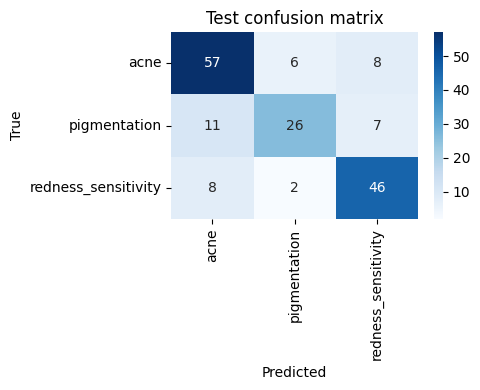


Accuracy by whether a face was detected in preprocessing:
  face detected: 0.745  (n=47)
  whole-image fallback: 0.758  (n=124)

Test set size: 171 -- with this few images a +/-5 point swing is within noise.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt, seaborn as sns

probs = model.predict(test_ds, verbose=0)
y_true = test_df["y"].values
y_pred = probs.argmax(1)

majority = np.bincount(train_df["y"]).argmax()
print(f"Majority-class baseline accuracy: {(y_true == majority).mean():.3f}")
print(f"Model accuracy:                    {(y_true == y_pred).mean():.3f}")
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Macro F1:                          {macro_f1:.3f}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix"); plt.tight_layout(); plt.show()

print("\nAccuracy by whether a face was detected in preprocessing:")
t = test_df.copy(); t["correct"] = (y_true == y_pred)
for flag, name in [(True, "face detected"), (False, "whole-image fallback")]:
    s = t[t["face_detected"] == flag]
    if len(s):
        print(f"  {name}: {s['correct'].mean():.3f}  (n={len(s)})")
print(f"\nTest set size: {len(test_df)} -- with this few images a +/-5 point swing is within noise.")


**How to read this:** compare against the majority baseline, not against 100%. Three classes on clinical close-ups
is an *easy* task (the categories look very different), so a high number here says little about real selfie
performance. The test that matters is on in-house selfies, which this notebook cannot provide.

## Step 8 — Export: Keras + TFLite (dynamic-range quantization) and check they agree

In [ ]:
KERAS_PATH = f"{LOCAL_MODEL}/aura_l2_condition_baseline.keras"
TFLITE_PATH = f"{LOCAL_MODEL}/aura_l2_condition_baseline.tflite"
LABELS_PATH = f"{LOCAL_MODEL}/aura_l2_condition_labels.json"

model.save(KERAS_PATH)
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
open(TFLITE_PATH, "wb").write(conv.convert())
json.dump({"classes": CLASSES, "input_size": IMG, "input_range": "0-255 float32 RGB",
           "output": "softmax over classes", "note": "No healthy-skin class. Baseline only."},
          open(LABELS_PATH, "w"), indent=2)

interp = tf.lite.Interpreter(model_path=TFLITE_PATH); interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]
xb, _ = next(iter(test_ds))
n = min(16, len(xb)); agree = 0
for i in range(n):
    interp.set_tensor(inp_d["index"], xb[i:i+1].numpy().astype("float32")); interp.invoke()
    p_tfl = interp.get_tensor(out_d["index"])[0]
    p_k = model.predict(xb[i:i+1], verbose=0)[0]
    agree += int(p_tfl.argmax() == p_k.argmax())
print(f"TFLite size: {os.path.getsize(TFLITE_PATH)/1e6:.1f} MB")
print(f"TFLite vs Keras top-1 agreement: {agree}/{n}")


Saved artifact at '/tmp/tmpd992b5v1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_244')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140626122967568: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140626122965264: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140629292088976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424974992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424974800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424975568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424975376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424975952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424976144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626424975184: TensorSpec(shape=(), dtype=tf.resource, name=

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite size: 4.6 MB
TFLite vs Keras top-1 agreement: 16/16


## Step 9 — Upload to Drive and verify after a fresh remount

In [ ]:
for p in (KERAS_PATH, TFLITE_PATH, LABELS_PATH):
    dst = os.path.join(DRIVE_MODEL_DIR, os.path.basename(p))
    shutil.copy2(p, dst); time.sleep(1)
    assert os.path.getsize(dst) == os.path.getsize(p), f"SIZE MISMATCH {p}"
print("✅ Copied and sizes match.")

drive.flush_and_unmount(); time.sleep(3); drive.mount('/content/drive')
for p in (KERAS_PATH, TFLITE_PATH, LABELS_PATH):
    dst = os.path.join(DRIVE_MODEL_DIR, os.path.basename(p))
    assert os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(p), f"MISSING AFTER REMOUNT: {dst}"
    print(f"  ✅ {os.path.basename(p)}  {os.path.getsize(dst)/1e6:.1f} MB")


✅ Copied and sizes match.
Mounted at /content/drive
  ✅ aura_l2_condition_baseline.keras  27.8 MB
  ✅ aura_l2_condition_baseline.tflite  4.6 MB
  ✅ aura_l2_condition_labels.json  0.0 MB


## Step 10 — Update the manifest (written last)

In [ ]:
manifest["model_training"] = {
    "generated_at_utc": pd.Timestamp.utcnow().isoformat(),
    "task_formulation": "3-way softmax (single positive per image); NOT multi-label",
    "classes": CLASSES,
    "dropped_label_keywords": DROP_LABEL_KEYWORDS,
    "images_after_cleaning": int(len(df)),
    "split_counts": {k: int(v) for k, v in df["split"].value_counts().items()},
    "split_method": f"StratifiedGroupKFold on dHash near-duplicate groups (Hamming<={HAM})",
    "test_accuracy": float((y_true == y_pred).mean()),
    "test_macro_f1": float(macro_f1),
    "majority_baseline_accuracy": float((y_true == majority).mean()),
    "tflite_path": f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.tflite",
    "limitations": [
        "No healthy-skin class; forced choice among 3 conditions.",
        "Trained on clinical images, not selfies; domain gap unmeasured.",
        "Dryness/oiliness and pore visibility not modeled.",
        "Not validated on Filipino skin tones; DermNet skews to lighter skin.",
    ],
}
with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest["model_training"], indent=2, default=str))


{
  "generated_at_utc": "2026-10-13T05:13:25.253711+00:00",
  "task_formulation": "3-way softmax (single positive per image); NOT multi-label",
  "classes": [
    "acne",
    "pigmentation",
    "redness_sensitivity"
  ],
  "dropped_label_keywords": [
    "basal cell",
    "carcinoma",
    "keratosis",
    "nevus comedonicus",
    "pigmented bands"
  ],
  "images_after_cleaning": 900,
  "split_counts": {
    "train": 549,
    "val": 180,
    "test": 171
  },
  "split_method": "StratifiedGroupKFold on dHash near-duplicate groups (Hamming<=6)",
  "test_accuracy": 0.7543859649122807,
  "test_macro_f1": 0.7428338856910285,
  "majority_baseline_accuracy": 0.4152046783625731,
  "tflite_path": "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition/models/aura_l2_condition_baseline.tflite",
  "limitations": [
    "No healthy-skin class; forced choice among 3 conditions.",
    "Trained on clinical images, not selfies; domain gap unmeasured.",
    "Dryness/oiliness and pore visibility not mo

## Done — what to do next
1. Read the test numbers against the **majority baseline** and the per-class recall.
2. Check the confusion matrix: if `redness_sensitivity` and `acne` are confused, the labels overlap visually.
3. Ask for the **task summary cell** and paste it here as the last markdown cell.

**Next (L2_T4):** evaluate on selfie-style images (you will need a small in-house or SCIN set) to measure the
clinical-to-selfie gap, and add datasets with negatives so a real multi-label head becomes possible.

# L2_T3 Task Summary: Baseline Condition Classifier

## Goal
Train a first working skin-condition classifier on the preprocessed DermNet set from L2_T2 and export it as TFLite. This is a baseline that proves the Layer 2 pipeline end to end. It is not a product model.

## Process
1. Loaded the L2_T2 archive, copied it to local disk, and extracted it. 983 images, verified against the manifest.
2. **Cleaned the labels.** Dropped the contamination found in the T2 review: `basal cell carcinoma pigmented` (60), `actinic keratosis pigmented` (9), `pigmented bands` (8) and `nevus comedonicus` (6). 983 images became 900.
3. **Split without leakage.** Near-duplicates were grouped by perceptual hash (dHash, Hamming ≤ 6): 853 groups from 900 images. Whole groups were assigned to train, val or test with `StratifiedGroupKFold`. A check confirmed that no group spans two splits.
4. **Trained EfficientNet-B0** with class weights and mild augmentation. There was no hue or saturation jitter, because colour is the signal for redness and pigmentation.
   - Stage 1: frozen backbone, head only, 15 epochs.
   - Stage 2: top 20 layers unfrozen, BatchNorm frozen, lr 1e-5, 15 epochs.
5. Evaluated once on the held-out test split.
6. Exported Keras and TFLite (dynamic-range quantization). Uploaded to Drive and verified after a fresh remount. Wrote the manifest last.

## Task Formulation (a correction to the earlier plan)
This is a **3-way softmax**, not a masked multi-label model. DermNet gives each image exactly one positive and unknown for everything else. A masked multi-label loss on that data has no negatives, so it would collapse to predicting every condition. Multi-label needs datasets that carry negatives.

## Accomplished
| Item | Result |
|---|---|
| Images after cleaning | 900 (acne 368, redness_sensitivity 311, pigmentation 221) |
| Split | train 549 / val 180 / test 171 |
| Majority-class baseline (test) | 41.5% |
| **Test accuracy** | **75.4%** |
| **Test macro F1** | **0.743** |
| Final validation accuracy | 85.6% |
| TFLite size | 4.6 MB (Keras 27.8 MB) |
| TFLite vs Keras top-1 agreement | 16/16 |
| Drive verification | Keras, TFLite and labels JSON confirmed after remount |

Per-class test results:
| Class | Precision | Recall | F1 | n |
|---|---|---|---|---|
| acne | 0.750 | 0.803 | 0.776 | 71 |
| pigmentation | 0.765 | **0.591** | 0.667 | 44 |
| redness_sensitivity | 0.754 | 0.821 | 0.786 | 56 |

Accuracy by face detection: face detected 74.5% (n=47), whole-image fallback 75.8% (n=124). The two are about equal, so the face crop did not noticeably help or hurt.

## How to Read These Numbers
- The model beats the majority baseline by about 34 points, so it learned real signal.
- **Validation (85.6%) is about 10 points above test (75.4%).** Early stopping and model selection used the validation split, which makes it optimistic. Treat **75.4% as the number to quote**.
- The test set has 171 images, so a swing of about ±6 points is within noise.
- **Pigmentation is the weakest class.** Recall is 59%, and it has the fewest images (221). It is the class most likely to be missed.
- This is a three-way task on clinical close-ups, which is easy because the categories look very different. It says little about real selfie performance.

## Not Included, and Why
- **Dryness/oiliness and pore visibility:** no source data.
- **Healthy-skin class:** none exists in DermNet. A clear-skin selfie will still be forced into one of the three conditions.
- **Multi-label output and severity grading:** DermNet has no negatives and no severity labels.
- **Selfie-domain evaluation:** no selfie-style images yet, so the clinical-to-selfie gap is unmeasured.
- **Skin-tone fairness evaluation:** DermNet has no skin-tone labels and skews toward lighter skin. Performance on Filipino skin tones is unknown.
- **Per-zone analysis:** no zone annotations.

## Known Issues
1. The model must **not be shown to users** as a diagnosis or a skin score.
2. Pigmentation recall of 59% is below any usable bar.
3. `tf.lite.Interpreter` is deprecated. The export works, but migrate to `ai_edge_litert` before the app integration.
4. DermNet's mirror states no license, so treat the model as research-only.

## Status
The baseline is trained, exported, and verified on Drive. The pipeline works end to end. The model itself is not ready for use beyond research.

## Next (L2_T4)
Measure the clinical-to-selfie gap on selfie-style images (SCIN or a small in-house set), include skin-tone stratification in that evaluation, and bring in datasets with negatives so a real multi-label head becomes possible.